# Chest X-Ray Pneumonia Classification: an end-to-end ML pipeline

**Goal:** classify chest X-rays as `Normal` or `Pneumonia`, then serve the model through an API + UI with retraining.

**This notebook covers:** data acquisition and cleaning, data visualisation (with interpretation), preprocessing, a baseline model, an optimised transfer-learning model, evaluation with 6 metrics, and prediction functions.

| Stage | Where |
|---|---|
| Data acquisition | `scripts/download_data.py` |
| Data processing | `src/preprocessing.py` |
| Model creation / testing | `src/model.py` (+ this notebook) |
| Prediction | `src/prediction.py` |

> This is a learning project, not a medical device. A real diagnostic model needs clinical validation.

In [ ]:
import sys, random
sys.path.append("..")   

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from PIL import Image
from IPython.display import display
from sklearn.metrics import roc_curve

from src.preprocessing import (
    TRAIN_DIR, TEST_DIR, IMG_SIZE, clean_dataset, count_images,
    get_class_names, load_train_val, load_test, get_augmentation,
)
from src import model as M
from src import prediction as P

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
sns.set_theme(style="whitegrid")
print("TensorFlow:", tf.__version__)

TensorFlow: 2.15.0


## 1. Data acquisition and cleaning

The data comes from the Kaggle *Chest X-Ray Images (Pneumonia)* dataset. `scripts/download_data.py` downloads it, keeps Kaggle's own train/test split (so the same patient never appears in both), merges the tiny 16-image validation folder into train, resizes images to 256x256 and writes them to `data/train` and `data/test`.

**Why clean?** One corrupt file would crash `tf.data` in the middle of an epoch, so we verify every image first.

In [7]:
print("Corrupt images removed (train):", clean_dataset(TRAIN_DIR))
print("Corrupt images removed (test): ", clean_dataset(TEST_DIR))

class_names = get_class_names()
train_counts, test_counts = count_images(TRAIN_DIR), count_images(TEST_DIR)
print("Classes:", class_names)
print("Train:", train_counts)
print("Test: ", test_counts)

Corrupt images removed (train): 0
Corrupt images removed (test):  0
Classes: ['Normal', 'Pneumonia']
Train: {'Normal': 1349, 'Pneumonia': 2000}
Test:  {'Normal': 234, 'Pneumonia': 390}


## 2. Data visualisation: what story does the data tell?

### Feature 1: class balance

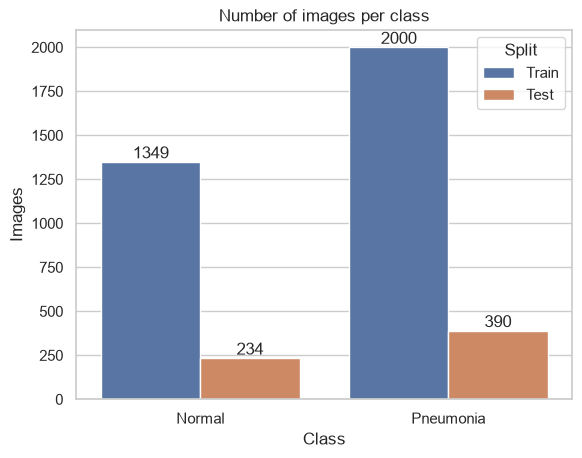

Pneumonia : Normal ratio -> train 1.48, test 1.67


In [5]:
df_counts = pd.DataFrame({"Train": train_counts, "Test": test_counts}).reset_index().melt(
    id_vars="index", var_name="Split", value_name="Images").rename(columns={"index": "Class"})
ax = sns.barplot(data=df_counts, x="Class", y="Images", hue="Split")
for c in ax.containers:
    ax.bar_label(c)
plt.title("Number of images per class")
plt.show()

ratio_train = train_counts["Pneumonia"] / train_counts["Normal"]
ratio_test = test_counts["Pneumonia"] / test_counts["Normal"]
print(f"Pneumonia : Normal ratio -> train {ratio_train:.2f}, test {ratio_test:.2f}")

**Interpretation (class balance).** Pneumonia images outnumber normal ones in both splits. A model that always answered "Pneumonia" would already look decent on accuracy alone, so **accuracy is not enough** here. That is why we (a) use class weights during training and (b) judge the model with precision, recall, F1 and AUC. In a medical setting, *recall on Pneumonia* matters most: a missed case (false negative) is worse than a false alarm.

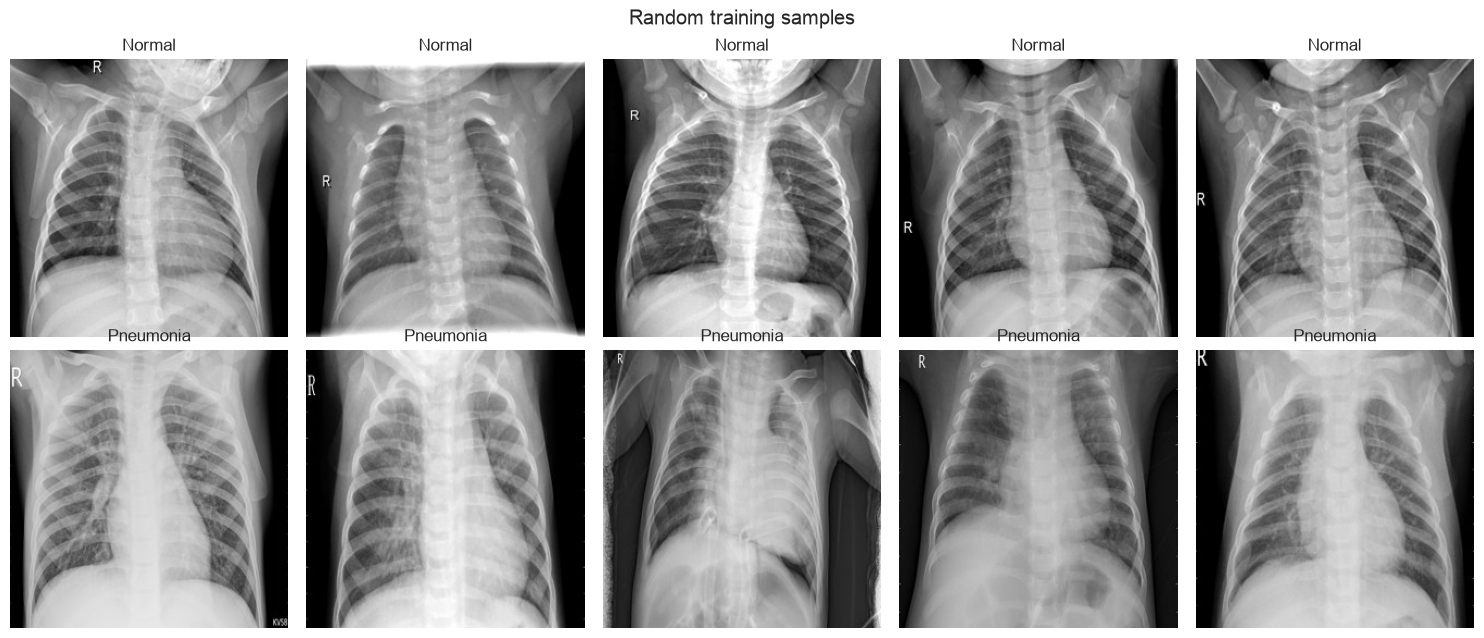

In [10]:
# A look at the raw material: 5 random images per class
fig, axes = plt.subplots(2, 5, figsize=(15, 6.5))
for r, cls in enumerate(class_names):
    files = random.sample(list((TRAIN_DIR / cls).glob("*.jpg")), 5)
    for c, f in enumerate(files):
        axes[r, c].imshow(Image.open(f).convert("L"), cmap="gray")
        axes[r, c].set_title(cls); axes[r, c].axis("off")
plt.suptitle("Random training samples")
plt.tight_layout(); plt.show()

### Features 2-4: brightness, contrast and central-lung brightness

We turn each image into three numbers computed on a random sample of 300 images per class:
- **brightness**: mean pixel intensity (0 = black, 255 = white)
- **contrast**: standard deviation of pixel intensity
- **centre brightness**: mean intensity of the middle of the image, where the lungs sit. Pneumonia shows up as cloudy, white-ish patches (opacities), so this should differ.

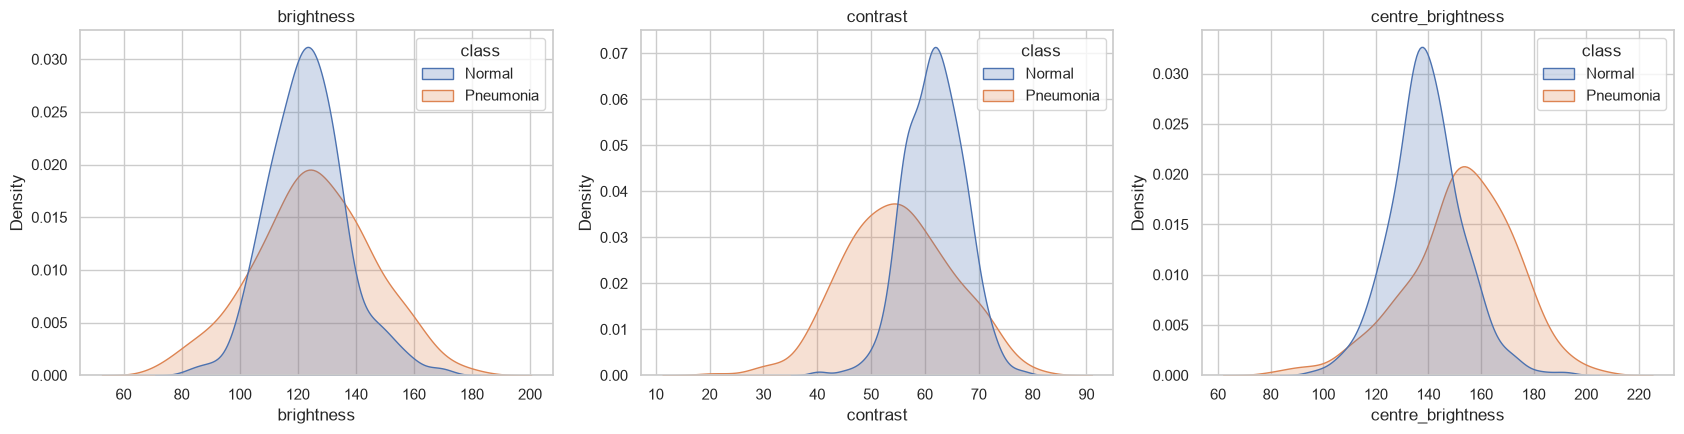

,brightness,contrast,centre_brightness
class,,,
Normal,123.199997,61.700001,139.000000
Pneumonia,125.400002,55.000000,152.300003


- brightness: Pneumonia scores higher (125.4 vs 123.2 for Normal, gap 2.2)
- contrast: Normal scores higher (61.7 vs 55.0 for Pneumonia, gap 6.7)
- centre_brightness: Pneumonia scores higher (152.3 vs 139.0 for Normal, gap 13.3)


In [11]:
def image_features(path):
    arr = np.asarray(Image.open(path).convert("L"), dtype="float32")
    h, w = arr.shape
    centre = arr[h // 4: 3 * h // 4, w // 4: 3 * w // 4]
    return {"brightness": arr.mean(), "contrast": arr.std(), "centre_brightness": centre.mean()}

rows = []
for cls in class_names:
    files = list((TRAIN_DIR / cls).glob("*.jpg"))
    for f in random.sample(files, min(300, len(files))):
        rows.append({"class": cls, **image_features(f)})
feat = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, ["brightness", "contrast", "centre_brightness"]):
    sns.kdeplot(data=feat, x=col, hue="class", fill=True, common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

summary = feat.groupby("class")[["brightness", "contrast", "centre_brightness"]].mean().round(1)
display(summary)
for col in summary.columns:
    hi, lo = summary[col].idxmax(), summary[col].idxmin()
    print(f"- {col}: {hi} scores higher ({summary[col].max():.1f} vs {summary[col].min():.1f} "
          f"for {lo}, gap {summary[col].max() - summary[col].min():.1f})")

**Interpretation (brightness, contrast, centre brightness).**
- *Centre brightness* is the most medically meaningful of the three: fluid and inflammation in the lungs absorb more X-ray, which appears as brighter, cloudier regions in the lung area. If the pneumonia curve sits to the right, that matches the clinical picture.
- *Brightness* and *contrast* also shift, but the curves **overlap heavily**. Overall exposure also depends on the X-ray machine, patient size and positioning, so these simple statistics are noisy.
- **Story:** no single hand-made feature separates the classes cleanly. The differences are in *where* and *what shape* the opacities take, which is a spatial pattern. That is exactly what a convolutional network learns, and it justifies using a CNN instead of a classic ML model on summary statistics.

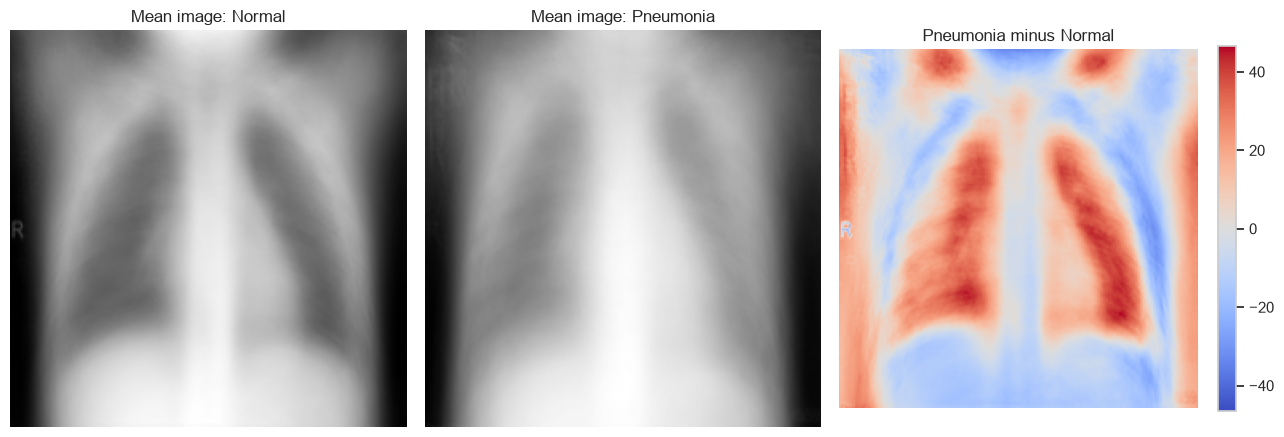

In [12]:
# Average image per class: pixel-by-pixel mean of 200 images
fig, axes = plt.subplots(1, 3, figsize=(13, 4.5))
means = {}
for cls in class_names:
    files = random.sample(list((TRAIN_DIR / cls).glob("*.jpg")), 200)
    means[cls] = np.mean([np.asarray(Image.open(f).convert("L").resize(IMG_SIZE), dtype="float32") for f in files], axis=0)
for ax, cls in zip(axes, class_names):
    ax.imshow(means[cls], cmap="gray"); ax.set_title(f"Mean image: {cls}"); ax.axis("off")
diff = means["Pneumonia"] - means["Normal"]
im = axes[2].imshow(diff, cmap="coolwarm", vmin=-np.abs(diff).max(), vmax=np.abs(diff).max())
axes[2].set_title("Pneumonia minus Normal"); axes[2].axis("off")
plt.colorbar(im, ax=axes[2], fraction=0.046)
plt.tight_layout(); plt.show()

**Interpretation (mean images).** The red areas in the difference map are where pneumonia X-rays are, on average, brighter than normal ones

## 3. Data preprocessing

| Step | What | Why |
|---|---|---|
| Resize to 224x224 | all images, done in the `tf.data` pipeline | MobileNetV2's native input size |
| Convert to RGB | done at save time | pretrained weights expect 3 channels |
| Rescale to [-1, 1] | **inside the model** (`Rescaling` layer) | training and serving can't disagree about scaling |
| Train/validation split | 80/20 of train, fixed seed | validation drives early stopping; test stays untouched until the end |
| Augmentation | flip, small rotation, zoom, contrast (train only) | more variety, less overfitting. No vertical flips: X-rays always have the same orientation |
| Class weights | rarer class weighs more in the loss | counteracts the imbalance |
| Cache/prefetch | `tf.data` prefetch | keeps the CPU/GPU busy |

In [13]:
train_ds, val_ds = load_train_val(class_names=class_names)
test_ds = load_test(class_names=class_names)
class_weight = M.compute_class_weights()
print("Class weights:", {class_names[k]: round(v, 3) for k, v in class_weight.items()})

Found 3349 files belonging to 2 classes.
Using 2680 files for training.
Found 3349 files belonging to 2 classes.
Using 669 files for validation.
Found 624 files belonging to 2 classes.
Class weights: {'Normal': 1.241, 'Pneumonia': 0.837}


Found 3349 files belonging to 2 classes.
Using 2680 files for training.
Found 3349 files belonging to 2 classes.
Using 669 files for validation.


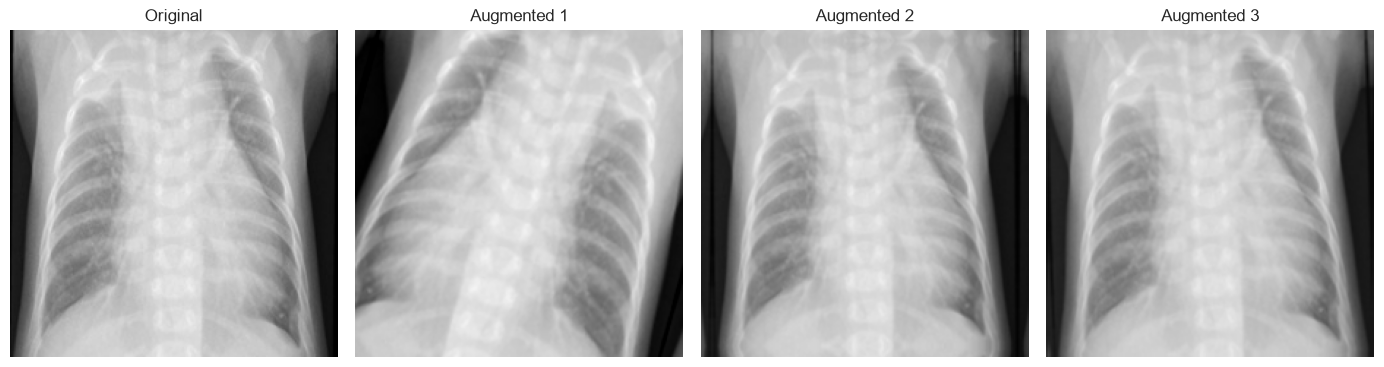

In [ ]:
raw_ds, _ = load_train_val(class_names=class_names, augment=False)
images, labels = next(iter(raw_ds))
aug = get_augmentation()
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
axes[0].imshow(images[0].numpy().astype("uint8")); axes[0].set_title("Original")
for i in range(1, 4):
    axes[i].imshow(aug(images[:1], training=True)[0].numpy().astype("uint8")); axes[i].set_title(f"Augmented {i}")
for a in axes: a.axis("off")
plt.tight_layout(); plt.show()

## 4. Baseline model (no optimisation)

A small CNN trained from scratch with no dropout, no regularisation, no pretrained weights. **Why?** To have an honest reference point: if the optimised model cannot beat this, the optimisation techniques are not earning their keep.

In [15]:
EPOCHS_BASELINE = 8
EPOCHS_HEAD = 10        # phase 1 of the optimised model
EPOCHS_FINETUNE = 10    # phase 2 of the optimised model

baseline = M.build_baseline_cnn(len(class_names))
M.compile_model(baseline, lr=1e-3)
hist_base = baseline.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_BASELINE,
                         callbacks=M.get_callbacks(patience=3))

Epoch 1/8
84/84 [==============================] - 103s 1s/step - loss: 0.6830 - accuracy: 0.6590 - val_loss: 0.3128 - val_accuracy: 0.8655 - lr: 0.0010
Epoch 2/8
84/84 [==============================] - 93s 1s/step - loss: 0.3831 - accuracy: 0.8373 - val_loss: 0.2124 - val_accuracy: 0.9133 - lr: 0.0010
Epoch 3/8
84/84 [==============================] - 91s 1s/step - loss: 0.2927 - accuracy: 0.8709 - val_loss: 0.2078 - val_accuracy: 0.9253 - lr: 0.0010
Epoch 4/8
84/84 [==============================] - 108s 1s/step - loss: 0.2973 - accuracy: 0.8795 - val_loss: 0.2950 - val_accuracy: 0.8969 - lr: 0.0010
Epoch 5/8
84/84 [==============================] - 94s 1s/step - loss: 0.2487 - accuracy: 0.8996 - val_loss: 0.1713 - val_accuracy: 0.9387 - lr: 0.0010
Epoch 6/8
84/84 [==============================] - 109s 1s/step - loss: 0.2263 - accuracy: 0.9112 - val_loss: 0.1430 - val_accuracy: 0.9462 - lr: 0.0010
Epoch 7/8
84/84 [==============================] - 123s 1s/step - loss: 0.2135 - accu

## 5. Optimised model: transfer learning with MobileNetV2

**Optimisation techniques used:**

1. **Pretrained model (transfer learning):** MobileNetV2 already knows edges, textures and shapes from ImageNet. We reuse that instead of learning from ~3,300 images.
2. **Two-phase training:** (1) train only the new classification head with a normal learning rate; (2) *fine-tune* the top 30 layers with a tiny learning rate (1e-5) so the pretrained features adapt gently to X-rays without being destroyed.
3. **Regularisation:** two dropout layers (0.4) and L2 weight decay on the dense layer to fight overfitting.
4. **Optimiser:** Adam, with **ReduceLROnPlateau** shrinking the learning rate when validation loss stalls.
5. **Early stopping:** stops when validation loss stops improving and restores the best weights.
6. **Class weights** for the imbalance and **data augmentation** (see section 3).

In [16]:
model = M.build_model(num_classes=len(class_names))
model.summary()

9406464/9406464 [==============================] - 2s 0us/step
Model: "pneumonia_mobilenetv2"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 image (InputLayer)          [(None, 224, 224, 3)]     0         
                                                                 
 rescale (Rescaling)         (None, 224, 224, 3)       0         
                                                                 
 mobilenetv2_1.00_224 (Func  (None, 7, 7, 1280)        2257984   
 tional)                                                         
                                                                 
 global_average_pooling2d (  (None, 1280)              0         
 GlobalAveragePooling2D)                                         
                                                                 
 dropout (Dropout)           (None, 1280)              0         
                                                

In [17]:
h_head, h_ft = M.train_two_phase(
    model, train_ds, val_ds, class_weight=class_weight,
    epochs_head=EPOCHS_HEAD, epochs_finetune=EPOCHS_FINETUNE,
)

Epoch 1/10
84/84 [==============================] - 48s 472ms/step - loss: 0.3920 - accuracy: 0.8433 - val_loss: 0.1727 - val_accuracy: 0.9372 - lr: 0.0010
Epoch 2/10
84/84 [==============================] - 40s 423ms/step - loss: 0.2376 - accuracy: 0.9112 - val_loss: 0.1651 - val_accuracy: 0.9402 - lr: 0.0010
Epoch 3/10
84/84 [==============================] - 41s 425ms/step - loss: 0.2285 - accuracy: 0.9194 - val_loss: 0.1588 - val_accuracy: 0.9447 - lr: 0.0010
Epoch 4/10
84/84 [==============================] - 42s 436ms/step - loss: 0.1964 - accuracy: 0.9313 - val_loss: 0.1644 - val_accuracy: 0.9417 - lr: 0.0010
Epoch 5/10
84/84 [==============================] - 49s 500ms/step - loss: 0.2008 - accuracy: 0.9269 - val_loss: 0.1456 - val_accuracy: 0.9507 - lr: 0.0010
Epoch 6/10
84/84 [==============================] - 42s 440ms/step - loss: 0.1818 - accuracy: 0.9321 - val_loss: 0.1509 - val_accuracy: 0.9552 - lr: 0.0010
Epoch 7/10
84/84 [==============================] - 44s 461ms/st

Epoch 1/10
84/84 [==============================] - 54s 543ms/step - loss: 0.1687 - accuracy: 0.9422 - val_loss: 0.1296 - val_accuracy: 0.9596 - lr: 1.0000e-05
Epoch 2/10
84/84 [==============================] - 53s 556ms/step - loss: 0.1457 - accuracy: 0.9485 - val_loss: 0.1211 - val_accuracy: 0.9671 - lr: 1.0000e-05
Epoch 3/10
84/84 [==============================] - 52s 557ms/step - loss: 0.1312 - accuracy: 0.9560 - val_loss: 0.1194 - val_accuracy: 0.9641 - lr: 1.0000e-05
Epoch 4/10
84/84 [==============================] - 51s 544ms/step - loss: 0.1255 - accuracy: 0.9571 - val_loss: 0.1145 - val_accuracy: 0.9701 - lr: 1.0000e-05
Epoch 5/10
84/84 [==============================] - 51s 540ms/step - loss: 0.1236 - accuracy: 0.9575 - val_loss: 0.1173 - val_accuracy: 0.9671 - lr: 1.0000e-05
Epoch 6/10
84/84 [==============================] - 52s 560ms/step - loss: 0.1115 - accuracy: 0.9646 - val_loss: 0.1053 - val_accuracy: 0.9701 - lr: 1.0000e-05
Epoch 7/10
84/84 [======================

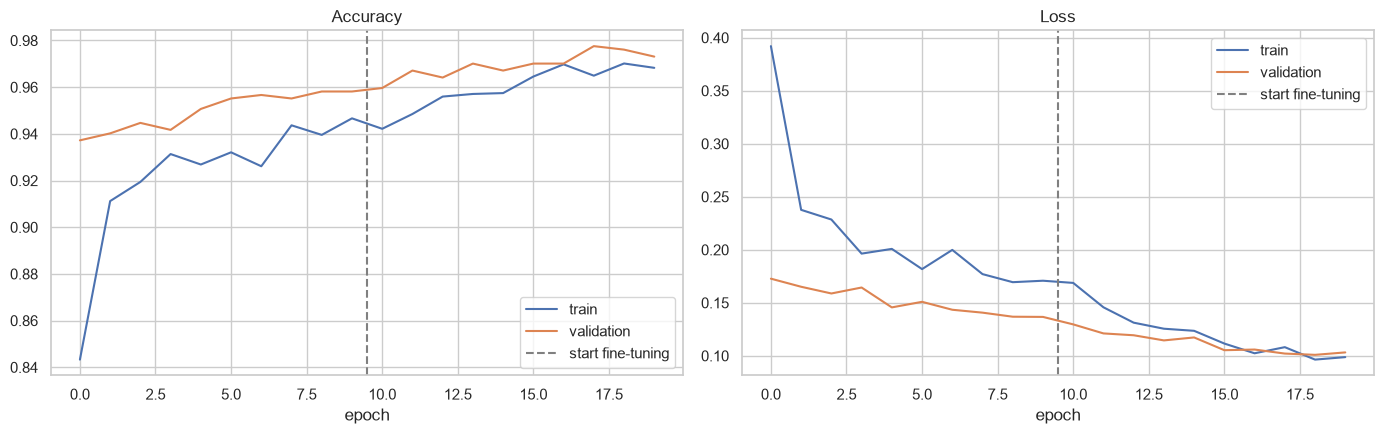

In [18]:
def merge_hist(*hs):
    out = {}
    for h in hs:
        for k, v in h.history.items():
            out.setdefault(k, []).extend(v)
    return out

hist = merge_hist(h_head, h_ft)
split_at = len(h_head.history["loss"])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, key, title in zip(axes, ["accuracy", "loss"], ["Accuracy", "Loss"]):
    ax.plot(hist[key], label="train")
    ax.plot(hist["val_" + key], label="validation")
    ax.axvline(split_at - 0.5, color="grey", linestyle="--", label="start fine-tuning")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
plt.tight_layout(); plt.show()

**How to read the curves.** If training and validation lines move together, the model generalises. A widening gap (training keeps improving, validation flat or worse) means overfitting, which dropout, augmentation and early stopping are there to limit. After the dashed line the model is fine-tuning: you often see a small extra improvement.

## 6. Evaluation on the held-out test set

The test set was never used for training, early stopping or tuning. We report **six metrics**: loss, accuracy, precision, recall, F1 and ROC-AUC. *Positive class = Pneumonia.*

- **Precision**: of the images predicted pneumonia, how many really are?
- **Recall (sensitivity)**: of the real pneumonia cases, how many did we catch? *(the critical one here)*
- **F1**: harmonic mean of precision and recall
- **AUC**: how well the model ranks pneumonia above normal across all thresholds

In [19]:
m_base, rep_base, _, _ = M.evaluate_model(baseline, test_ds, class_names)
m_opt, rep_opt, y_true, y_prob = M.evaluate_model(model, test_ds, class_names)

keys = ["loss", "accuracy", "precision", "recall", "f1", "auc"]
comparison = pd.DataFrame({
    "Baseline CNN": {k: m_base[k] for k in keys},
    "MobileNetV2 (optimised)": {k: m_opt[k] for k in keys},
}).round(4)
display(comparison)

,Baseline CNN,MobileNetV2 (optimised)
loss,0.7073,0.3781
accuracy,0.7692,0.8734
precision,0.7402,0.8373
recall,0.9718,0.9897
f1,0.8404,0.9072
auc,0.9166,0.9728


Classification report: optimised model

              precision    recall  f1-score   support

      Normal      0.975     0.679     0.801       234
   Pneumonia      0.837     0.990     0.907       390

    accuracy                          0.873       624
   macro avg      0.906     0.835     0.854       624
weighted avg      0.889     0.873     0.867       624



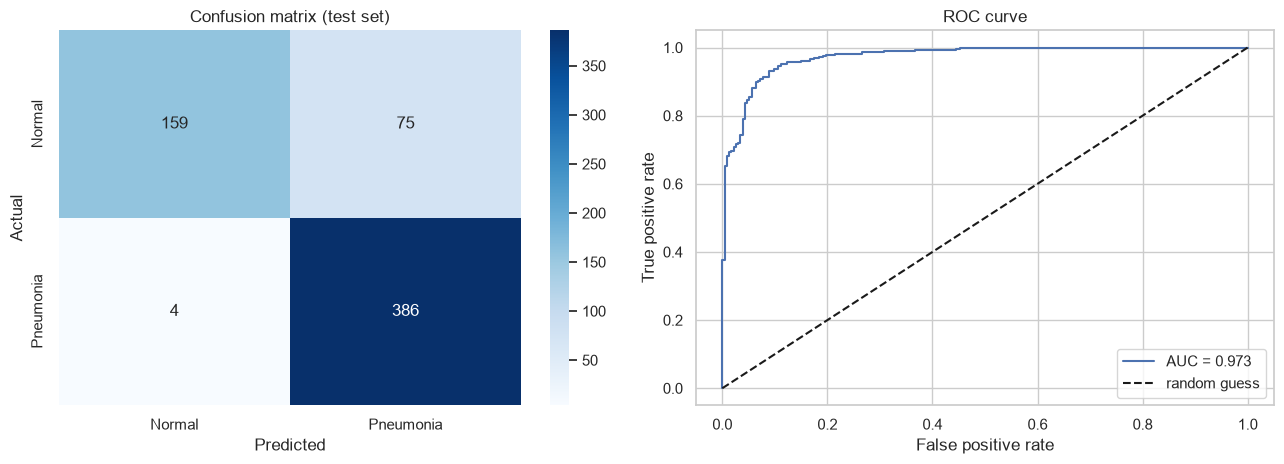

In [20]:
print("Classification report: optimised model\n")
print(rep_opt)

pos = class_names.index("Pneumonia")
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

sns.heatmap(np.array(m_opt["confusion_matrix"]), annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names, ax=axes[0])
axes[0].set_xlabel("Predicted"); axes[0].set_ylabel("Actual"); axes[0].set_title("Confusion matrix (test set)")

fpr, tpr, _ = roc_curve((y_true == pos).astype(int), y_prob[:, pos])
axes[1].plot(fpr, tpr, label=f"AUC = {m_opt['auc']:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", label="random guess")
axes[1].set_xlabel("False positive rate"); axes[1].set_ylabel("True positive rate")
axes[1].set_title("ROC curve"); axes[1].legend()
plt.tight_layout(); plt.show()

In [21]:
# Medical trade-off: moving the decision threshold changes precision vs recall
from sklearn.metrics import precision_score, recall_score
y_bin = (y_true == pos).astype(int)
rows = []
for t in [0.3, 0.5, 0.7, 0.9]:
    pred = (y_prob[:, pos] >= t).astype(int)
    rows.append({"threshold": t,
                 "precision": precision_score(y_bin, pred, zero_division=0),
                 "recall": recall_score(y_bin, pred, zero_division=0)})
display(pd.DataFrame(rows).round(3))

,threshold,precision,recall
0,0.3,0.806,0.992
1,0.5,0.837,0.990
2,0.7,0.865,0.982
3,0.9,0.926,0.956


**Interpretation.**

- **Optimised vs baseline:** the MobileNetV2 transfer-learning model beats the from-scratch CNN on every metric: accuracy 0.873 vs 0.769, F1 0.907 vs 0.840, AUC 0.973 vs 0.917, and test loss 0.378 vs 0.707. This confirms that pretrained features, regularisation, fine-tuning and class weights add real value.
- **Confusion matrix (optimised):** 386 pneumonia cases were caught and only 4 were missed (recall 0.990). However, 75 of 234 normal X-rays were flagged as pneumonia (Normal recall 0.679, Pneumonia precision 0.837). The model errs on the side of caution, which is the safer direction for a screening tool, but it would cause unnecessary follow-ups.
- **Validation vs test gap:** validation accuracy reached about 97%, but test accuracy is 87%. The validation split is drawn from the same pool as the training data (and may contain images from the same patients), whereas the Kaggle test set was collected separately, so this is likely a dataset shift. The high AUC (0.973) shows the model still ranks pneumonia above normal well; the loss comes mainly from the default 0.5 cut-off being poorly calibrated for the shifted test distribution.
- **Threshold table:** see the table above; raising the threshold trades some recall for fewer false alarms.
- **Limitations:** a single public dataset, no patient-level validation split, and no clinical validation. Results should not be read as diagnostic performance.

## 7. Save the model and prediction function

We save the model as `models/pneumonia_model.h5`, plus `class_names.json` (so index 0/1 always maps to the same label) and `metrics.json` (which the UI will display).

In [22]:
M.save_artifacts(model, class_names, metrics=m_opt)
print("Saved:", M.MODEL_PATH, f"({M.MODEL_PATH.stat().st_size / 1e6:.1f} MB)")

/opt/miniconda3/envs/pneumonia/lib/python3.11/site-packages/keras/src/engine/training.py:3103: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


Saved: /Users/ps2joystick/Desktop/ALU/ML_Pipeline/Summative/summative-pneumonia-mlops/models/pneumonia_model.h5 (23.5 MB)


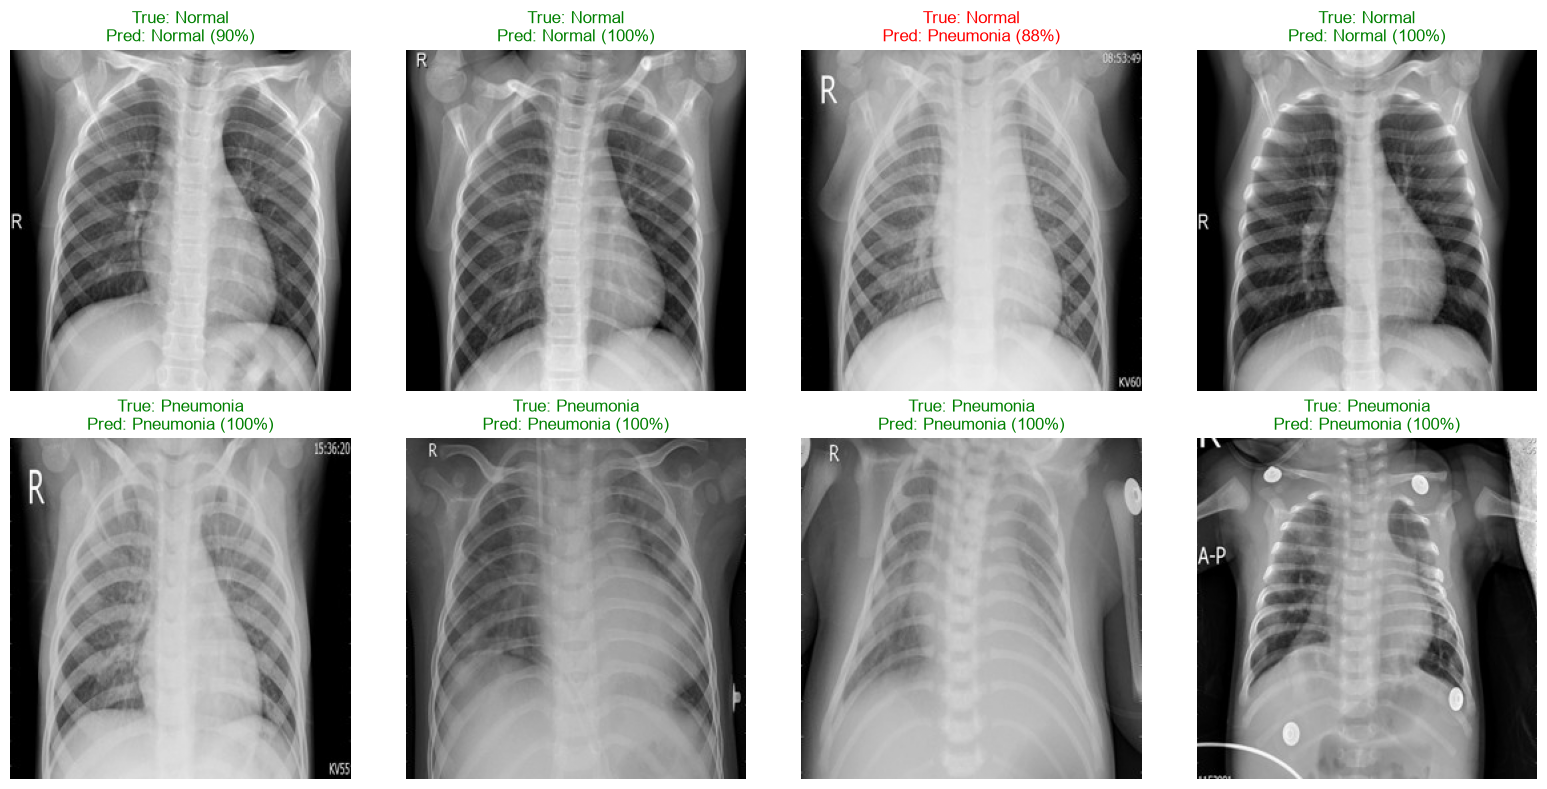

Correct on this sample: 7/8


In [ ]:
P.reload_model()

results = []
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for r, cls in enumerate(class_names):
    files = random.sample(list((TEST_DIR / cls).glob("*.jpg")), 4)
    for c, f in enumerate(files):
        out = P.predict_path(f)
        ok = out["label"] == cls
        results.append(ok)
        axes[r, c].imshow(Image.open(f).convert("L"), cmap="gray"); axes[r, c].axis("off")
        axes[r, c].set_title(f"True: {cls}\nPred: {out['label']} ({out['confidence']:.0%})",
                             color="green" if ok else "red")
plt.tight_layout(); plt.show()
print(f"Correct on this sample: {sum(results)}/{len(results)}")

## 8. Conclusions

- **What worked:** transfer learning + regularisation + fine-tuning gave a clearly stronger model than a from-scratch CNN.
- **What to watch:** class imbalance and dataset shift between the validation and test sets. Recall on Pneumonia is the key metric.
- **Limits:** a single public dataset, no clinical validation, and no explanation of *why* a prediction was made (Grad-CAM would be a natural extension).